# A Statistical Analysis of House Price Prediction
**Business Statistics Using Python (26MCAC103) · MCA Semester 1 · MIT-ADT University, Pune**

Descriptive statistics, correlation, hypothesis testing, simple & multiple regression, validation and prediction on a residential housing dataset (N = 1,500).

| | |
|---|---|
| Student | Divyanshuji Singh (ADT26COMM0753) |
| Supervisor | Dr. Pradnya Muley |
| Data | `housing.csv` (synthetic, created by `generate_data.py`, seed 42) |

**How to run:** `python generate_data.py` (once, to create `housing.csv`) → open this notebook → *Kernel ▸ Restart & Run All*. The `fig/` folder is created by the first code cell.

## Chapter 2 · Dataset and Methodology

Load the data, check its quality (types, missing values, duplicates, ranges) and create the derived variables `Area_100SqFt`, `Price_Category` and `BHK`.

In [1]:
# Listing 2.1: Import the library stack and set plotting defaults
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 150, 'savefig.bbox': 'tight'})
pd.set_option('display.width', 120)
pd.set_option('display.max_columns', None)
import os; os.makedirs('fig', exist_ok=True) # folder for saved figures
print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 3.0.6 | numpy 2.5.4


In [2]:
# Listing 2.2: Load the housing dataset and display the first records
df = pd.read_csv('housing.csv')
print('Shape:', df.shape)
print(df.head())

Shape: (1500, 10)
   House_ID  Price_Lakhs  Area_SqFt  Bedrooms  Bathrooms  Property_Age  Distance_to_Centre  Locality_Score  \
0         1        87.62       1730         3          2            10                11.3             3.2   
1         2        72.60       1220         2          1            11                 8.9             3.6   
2         3        61.15       1180         2          1            22                19.3             3.1   
3         4        76.84       1580         3          2             9                14.5             2.7   
4         5       103.17       1740         4          4             6                 4.4             3.5   

   Location_Zone   Zone_Type  
0  East Township    Suburban  
1   West Enclave       Urban  
2     Outer Ring  Peripheral  
3  East Township    Suburban  
4    Central CBD       Urban  


In [3]:
# Listing 2.3: Data types, missing values and duplicate checks
print(df.dtypes)
print('Missing cells:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('Duplicate House_IDs:', int(df['House_ID'].duplicated().sum()))

House_ID                int64
Price_Lakhs           float64
Area_SqFt               int64
Bedrooms                int64
Bathrooms               int64
Property_Age            int64
Distance_to_Centre    float64
Locality_Score        float64
Location_Zone             str
Zone_Type                 str
dtype: object
Missing cells: 0
Duplicate rows: 0
Duplicate House_IDs: 0


In [4]:
# Listing 2.4: Range screen for every numeric variable
num_cols = ['Price_Lakhs', 'Area_SqFt', 'Bedrooms', 'Bathrooms',
            'Property_Age', 'Distance_to_Centre', 'Locality_Score']
print(df[num_cols].agg(['min', 'max']).T)
print(df['Location_Zone'].value_counts())

                       min      max
Price_Lakhs          15.85   147.51
Area_SqFt           600.00  2360.00
Bedrooms              1.00     5.00
Bathrooms             1.00     5.00
Property_Age          0.00    40.00
Distance_to_Centre    0.50    28.70
Locality_Score        1.40     5.00
Location_Zone
Metro Suburb     299
IT Corridor      259
West Enclave     244
East Township    239
Outer Ring       235
Central CBD      224
Name: count, dtype: int64


In [5]:
# Listing 2.5: Cleaning, derived variables and price categories
df = df.dropna().drop_duplicates().copy()
df['Area_100SqFt'] = df['Area_SqFt'] / 100
df['Price_Category'] = np.where(df['Price_Lakhs'] < 65, 'Budget',
                       np.where(df['Price_Lakhs'] < 90, 'Mid-Segment', 'Premium'))
df['BHK'] = df['Bedrooms'].map({1: '1 BHK', 2: '2 BHK', 3: '3 BHK',
                                4: '4 BHK', 5: 'Penthouse'})
print(df['Price_Category'].value_counts())
print('Analytic N =', len(df))

Price_Category
Mid-Segment    708
Premium        442
Budget         350
Name: count, dtype: int64
Analytic N = 1500


## Chapter 3 · Descriptive Analysis

Centre, dispersion and shape of every numeric variable; price by location zone, BHK and zone type; Figures 3.1 – 3.4.

In [6]:
# Listing 3.1: Descriptive panel - centre, dispersion and shape
desc = df[num_cols].describe().T
desc['median'] = df[num_cols].median()
desc['skew'] = df[num_cols].skew()
desc['kurtosis'] = df[num_cols].kurt()
desc['cv_%'] = desc['std'] / desc['mean'] * 100
print(desc[['mean', 'median', 'std', 'min', 'max', 'skew', 'kurtosis', 'cv_%']].round(2))

                       mean   median     std     min      max  skew  kurtosis   cv_%
Price_Lakhs           79.49    79.70   19.95   15.85   147.51 -0.03     -0.11  25.09
Area_SqFt           1427.41  1440.00  303.56  600.00  2360.00 -0.02     -0.09  21.27
Bedrooms               2.97     3.00    1.07    1.00     5.00 -0.02     -0.58  35.98
Bathrooms              2.52     2.00    1.09    1.00     5.00  0.27     -0.70  43.22
Property_Age          10.77     9.00    7.00    0.00    40.00  1.17      1.56  64.97
Distance_to_Centre    10.47     9.25    6.75    0.50    28.70  0.56     -0.67  64.47
Locality_Score         3.47     3.50    0.62    1.40     5.00 -0.05     -0.30  17.75


In [7]:
# Listing 3.2: Mean, median and mode - the headline measures
print('Mean price (Rs lakhs):', round(df['Price_Lakhs'].mean(), 2))
print('Median price (Rs lakhs):', round(df['Price_Lakhs'].median(), 2))
print('Mean area (sq ft):', round(df['Area_SqFt'].mean(), 1))
print('Median area (sq ft):', df['Area_SqFt'].median())
print('Mode bedrooms:', df['Bedrooms'].mode().iloc[0], 'BHK')
print('Mode locality score:', df['Locality_Score'].mode().iloc[0])
q1, q3 = df['Price_Lakhs'].quantile([.25, .75])
print('Price Q1, Q3, IQR:', round(q1, 2), round(q3, 2), round(q3 - q1, 2))

Mean price (Rs lakhs): 79.49
Median price (Rs lakhs): 79.7
Mean area (sq ft): 1427.4
Median area (sq ft): 1440.0
Mode bedrooms: 3 BHK
Mode locality score: 3.2
Price Q1, Q3, IQR: 66.03 92.83 26.8


In [8]:
# Listing 3.3: Group summaries by location zone and BHK
zone_order = ['Central CBD', 'IT Corridor', 'West Enclave',
              'Metro Suburb', 'East Township', 'Outer Ring']
by_zone = df.groupby('Location_Zone')['Price_Lakhs'].agg(['count', 'mean', 'median', 'std'])
print(by_zone.loc[zone_order].round(2))
by_bhk = df.groupby('BHK')['Price_Lakhs'].agg(['count', 'mean', 'median'])
print(by_bhk.round(2))

               count   mean  median    std
Location_Zone                             
Central CBD      224  91.49   91.80  19.05
IT Corridor      259  85.21   85.34  18.49
West Enclave     244  81.90   81.85  17.84
Metro Suburb     299  76.53   76.16  18.59
East Township    239  74.64   74.96  18.84
Outer Ring       235  67.97   70.28  18.59
           count    mean  median
BHK                             
1 BHK        138   50.30   50.64
2 BHK        354   65.44   65.91
3 BHK        541   80.23   80.20
4 BHK        355   94.62   93.66
Penthouse    112  108.40  109.06


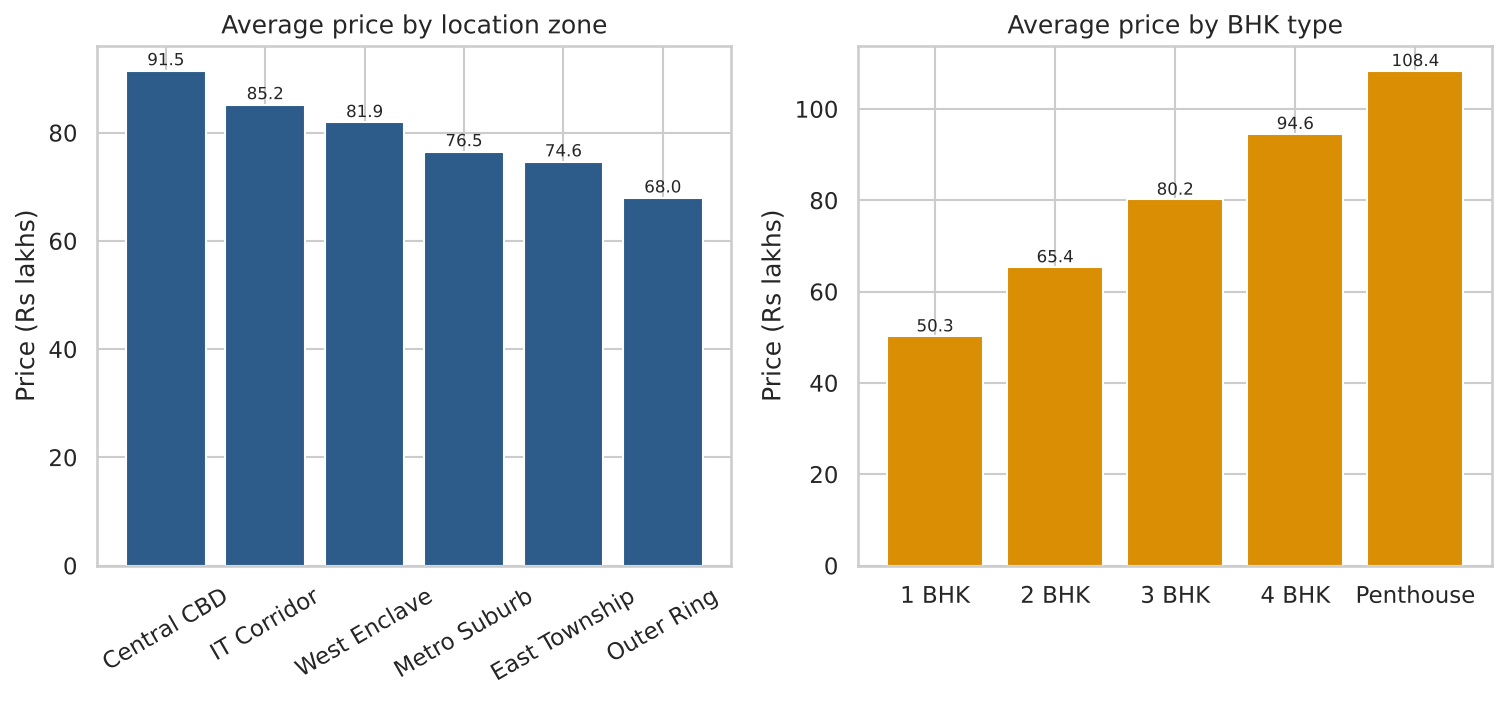

In [9]:
# Listing 3.4: Figure 3.1 - bar charts of average price by zone and BHK
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
zm = by_zone.loc[zone_order, 'mean']
ax[0].bar(zm.index, zm.values, color='#2E5C8A')
ax[0].set_title('Average price by location zone'); ax[0].set_ylabel('Price (Rs lakhs)')
ax[0].tick_params(axis='x', rotation=30)
for i, v in enumerate(zm.values):
    ax[0].text(i, v + 1, f'{v:.1f}', ha='center', fontsize=8)
bm = by_bhk['mean']
ax[1].bar(bm.index, bm.values, color='#D98E04')
ax[1].set_title('Average price by BHK type'); ax[1].set_ylabel('Price (Rs lakhs)')
for i, v in enumerate(bm.values):
    ax[1].text(i, v + 1, f'{v:.1f}', ha='center', fontsize=8)
plt.savefig('fig/fig3_1_bar.png'); plt.show()

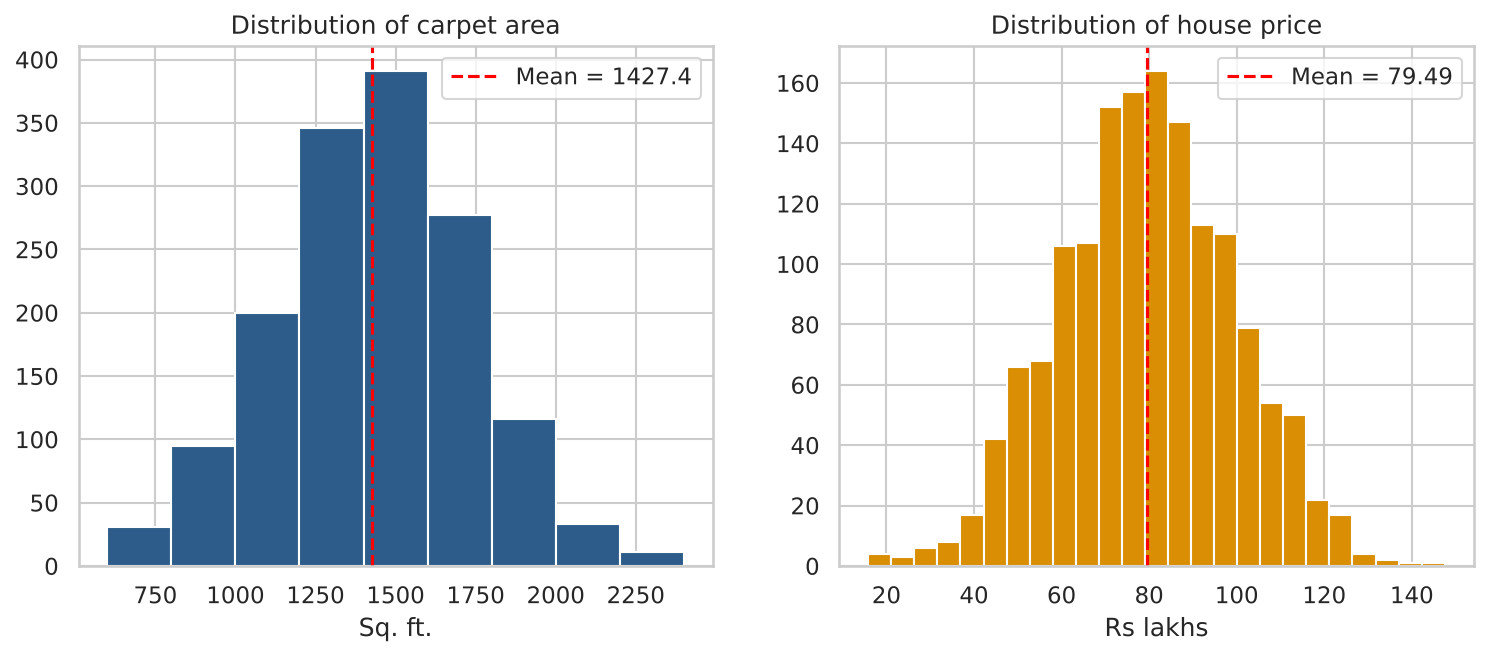

600-800       31
800-1000      95
1000-1200    200
1200-1400    346
1400-1600    391
1600-1800    277
1800-2000    116
2000-2200     33
2200-2400     11
dtype: int64


In [10]:
# Listing 3.5: Figure 3.2 - histograms of carpet area and price
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
bins = np.arange(600, 2600, 200)
counts, _, _ = ax[0].hist(df['Area_SqFt'], bins=bins, color='#2E5C8A', edgecolor='white')
ax[0].axvline(df['Area_SqFt'].mean(), color='red', ls='--',
              label=f"Mean = {df['Area_SqFt'].mean():.1f}")
ax[0].set_title('Distribution of carpet area'); ax[0].set_xlabel('Sq. ft.'); ax[0].legend()
ax[1].hist(df['Price_Lakhs'], bins=25, color='#D98E04', edgecolor='white')
ax[1].axvline(df['Price_Lakhs'].mean(), color='red', ls='--',
              label=f"Mean = {df['Price_Lakhs'].mean():.2f}")
ax[1].set_title('Distribution of house price'); ax[1].set_xlabel('Rs lakhs'); ax[1].legend()
plt.savefig('fig/fig3_2_hist.png'); plt.show()
print(pd.Series(counts.astype(int), index=[f'{a}-{a+200}' for a in bins[:-1]]))

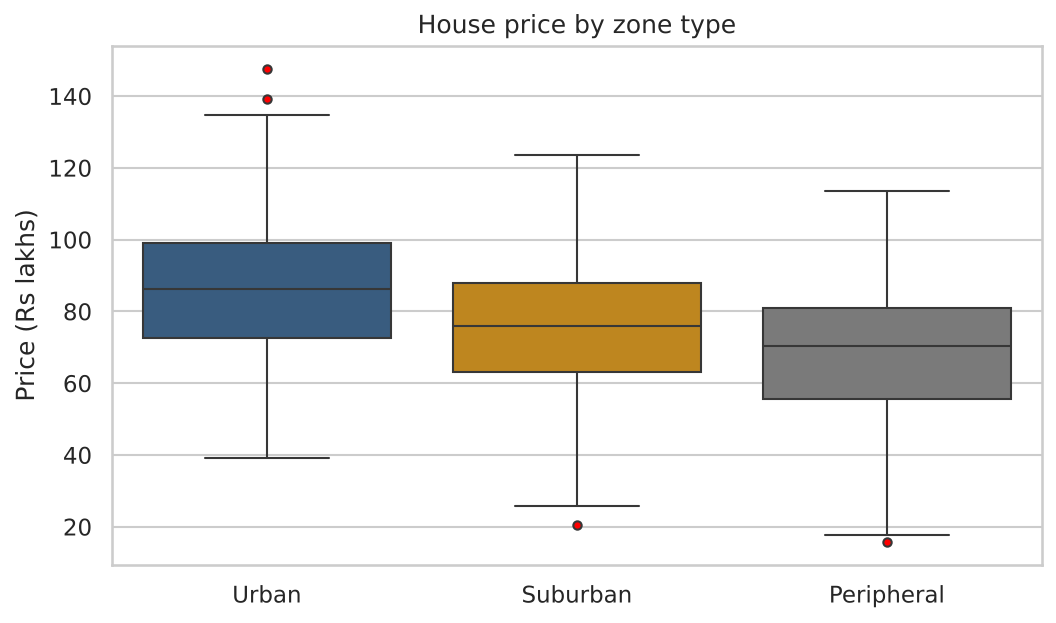

            count   mean    std    min    25%    50%    75%     max
Zone_Type                                                          
Urban       727.0  86.03  18.83  39.15  72.63  86.19  99.10  147.51
Suburban    538.0  75.69  18.71  20.50  63.06  75.97  88.06  123.69
Peripheral  235.0  67.97  18.59  15.85  55.70  70.28  81.00  113.63


In [11]:
# Listing 3.6: Figure 3.3 - box plot of Urban vs Suburban vs Peripheral prices
order = ['Urban', 'Suburban', 'Peripheral']
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df, x='Zone_Type', y='Price_Lakhs', order=order,
            palette=['#2E5C8A', '#D98E04', '#7A7A7A'],
            flierprops=dict(markerfacecolor='red', marker='o', markersize=4))
plt.title('House price by zone type'); plt.ylabel('Price (Rs lakhs)'); plt.xlabel('')
plt.savefig('fig/fig3_3_box.png'); plt.show()
print(df.groupby('Zone_Type')['Price_Lakhs'].describe().loc[order].round(2))

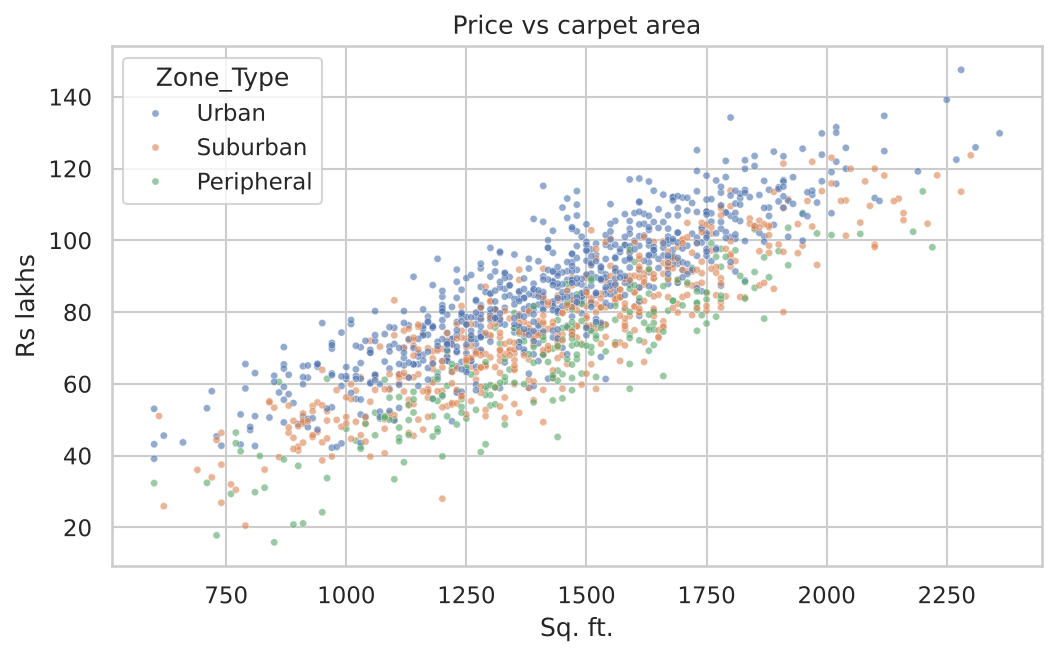

In [12]:
# Listing 3.7: Figure 3.4 - scatter of price against carpet area
plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=df, x='Area_SqFt', y='Price_Lakhs', hue='Zone_Type',
                hue_order=order, s=12, alpha=.6)
plt.title('Price vs carpet area'); plt.xlabel('Sq. ft.'); plt.ylabel('Rs lakhs')
plt.savefig('fig/fig3_4_scatter.png'); plt.show()

## Chapter 4 · Inferential Analysis

Normality tests, 95% confidence interval, Pearson/Spearman correlation, chi-square test (zone type × price category), Welch t-test and one-way ANOVA (α = 0.05).

Price_Lakhs    Shapiro W=0.9992 p=0.7874 | D'Agostino K2=1.01 p=0.6048
Area_SqFt      Shapiro W=0.9985 p=0.1934 | D'Agostino K2=0.56 p=0.7555
Property_Age   Shapiro W=0.9170 p=6.351e-28 | D'Agostino K2=279.30 p=2.241e-61


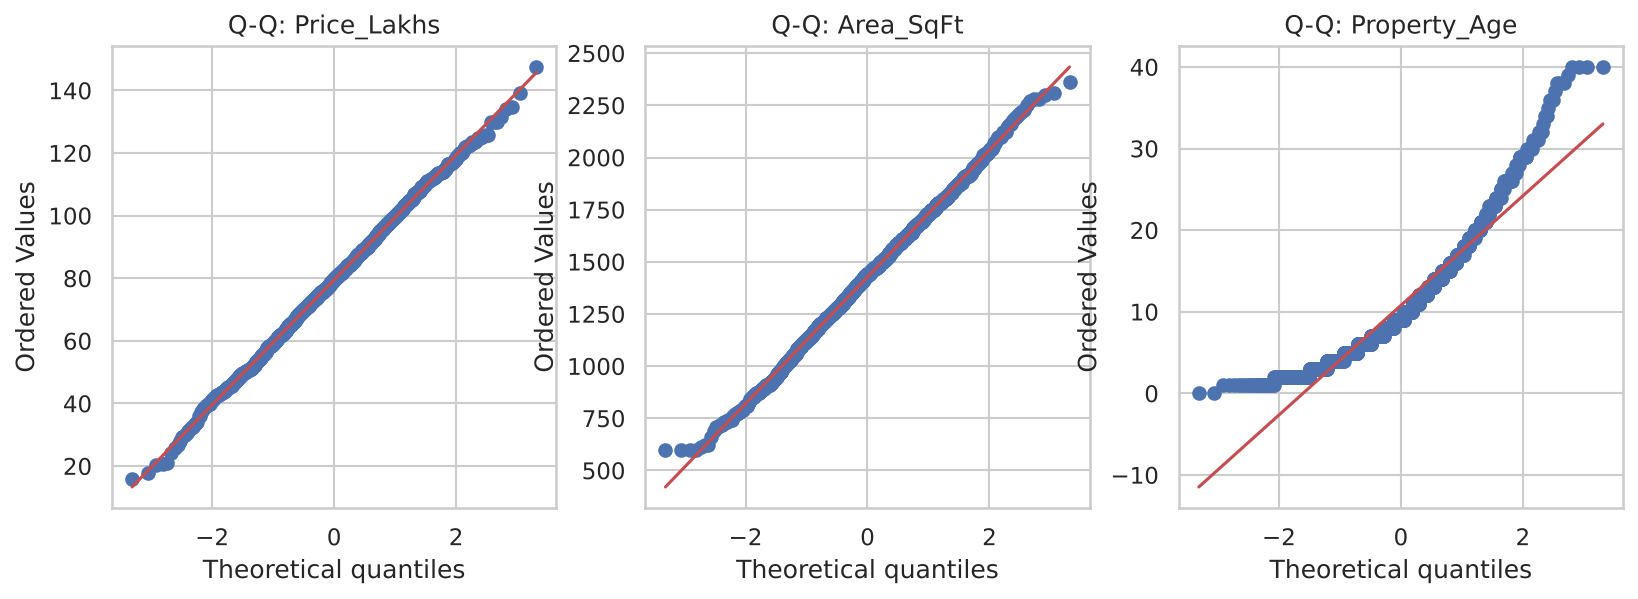

In [13]:
# Listing 4.1: Normality tests and Q-Q plots (Figure 4.1)
for c in ['Price_Lakhs', 'Area_SqFt', 'Property_Age']:
    w, p_sw = stats.shapiro(df[c])
    k, p_k = stats.normaltest(df[c])
    print(f'{c:14s} Shapiro W={w:.4f} p={p_sw:.4g} | D\'Agostino K2={k:.2f} p={p_k:.4g}')
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, c in zip(ax, ['Price_Lakhs', 'Area_SqFt', 'Property_Age']):
    stats.probplot(df[c], dist='norm', plot=a); a.set_title(f'Q-Q: {c}')
plt.savefig('fig/fig4_1_qq.png'); plt.show()

In [14]:
# Listing 4.2: 95% confidence interval for the mean house price
m = df['Price_Lakhs'].mean(); se = stats.sem(df['Price_Lakhs'])
lo, hi = stats.t.interval(0.95, len(df) - 1, loc=m, scale=se)
print(f'Mean = {m:.2f}, SE = {se:.3f}, 95% CI = ({lo:.2f}, {hi:.2f})')

Mean = 79.49, SE = 0.515, 95% CI = (78.48, 80.50)


In [15]:
# Listing 4.3: Pearson and Spearman correlation of area with price
r, p_r = stats.pearsonr(df['Area_SqFt'], df['Price_Lakhs'])
rho, p_rho = stats.spearmanr(df['Area_SqFt'], df['Price_Lakhs'])
print(f'Pearson r = {r:.4f} (p = {p_r:.3g})')
print(f'Spearman rho = {rho:.4f} (p = {p_rho:.3g})')

Pearson r = 0.8347 (p = 0)
Spearman rho = 0.8298 (p = 0)


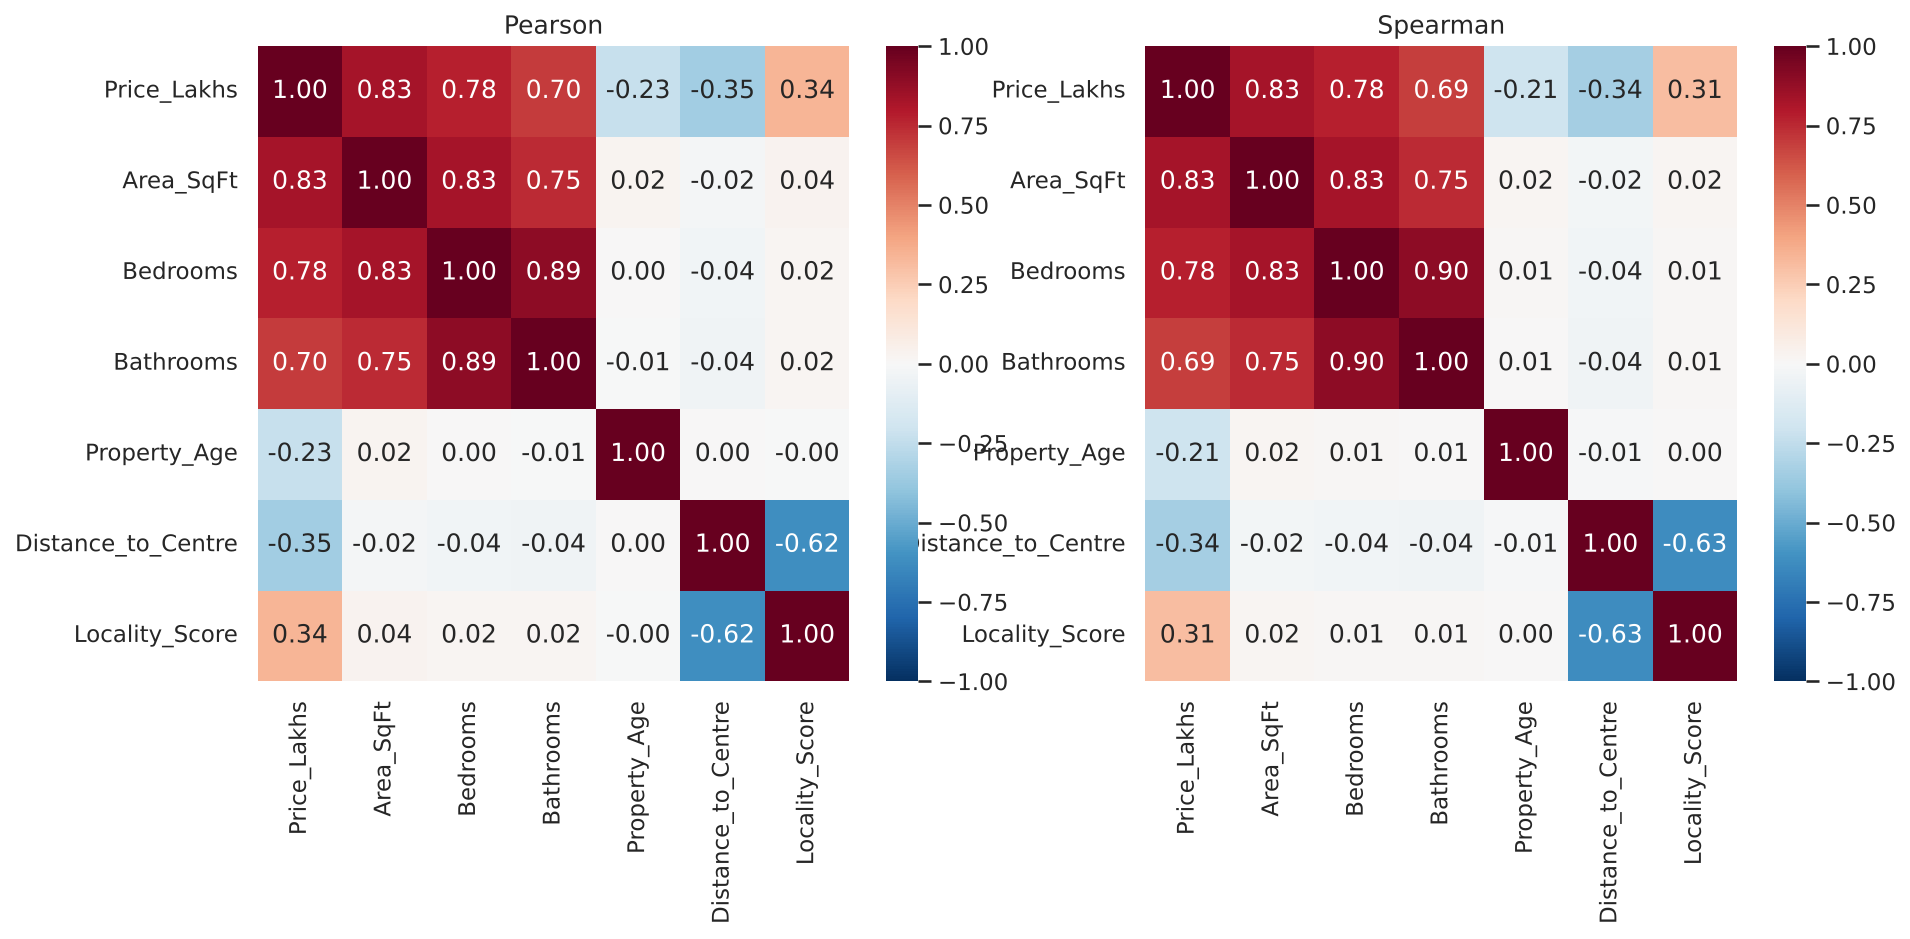

Area_SqFt             0.830
Bedrooms              0.777
Bathrooms             0.694
Distance_to_Centre   -0.340
Locality_Score        0.310
Property_Age         -0.208
Name: Price_Lakhs, dtype: float64


In [16]:
# Listing 4.4: Correlation matrices and ranked correlations (Figure 4.2)
corr_p = df[num_cols].corr(); corr_s = df[num_cols].corr(method='spearman')
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(corr_p, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title('Pearson')
sns.heatmap(corr_s, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title('Spearman')
plt.savefig('fig/fig4_2_corr.png'); plt.show()
print(corr_s['Price_Lakhs'].drop('Price_Lakhs').sort_values(key=abs, ascending=False).round(3))

In [17]:
# Listing 4.5: Chi-square test - zone type vs price category
observed = pd.crosstab(df['Zone_Type'], df['Price_Category']).loc[order]
chi2, p_chi, dof, expected = stats.chi2_contingency(observed)
n = observed.values.sum(); k = min(observed.shape) - 1
cramers_v = np.sqrt(chi2 / (n * k))
crit = stats.chi2.ppf(0.95, dof)
print(observed)
print(pd.DataFrame(expected, index=observed.index, columns=observed.columns).round(1))
print(f'chi2 = {chi2:.2f}, df = {dof}, critical(0.05) = {crit:.3f}, p = {p_chi:.3g}')
print(f"Cramer's V = {cramers_v:.3f}; min expected count = {expected.min():.1f}")

Price_Category  Budget  Mid-Segment  Premium
Zone_Type                                   
Urban              101          325      301
Suburban           150          272      116
Peripheral          99          111       25
Price_Category  Budget  Mid-Segment  Premium
Zone_Type                                   
Urban            169.6        343.1    214.2
Suburban         125.5        253.9    158.5
Peripheral        54.8        110.9     69.2
chi2 = 145.19, df = 4, critical(0.05) = 9.488, p = 2.18e-30
Cramer's V = 0.220; min expected count = 54.8


In [18]:
# Listing 4.6: Welch t-test - Urban vs Suburban prices
urb = df.loc[df['Zone_Type'] == 'Urban', 'Price_Lakhs']
sub = df.loc[df['Zone_Type'] == 'Suburban', 'Price_Lakhs']
t, p_t = stats.ttest_ind(urb, sub, equal_var=False)
pooled = np.sqrt((urb.var() + sub.var()) / 2); d = (urb.mean() - sub.mean()) / pooled
u, p_u = stats.mannwhitneyu(urb, sub)
print(f'Urban mean {urb.mean():.2f}, median {urb.median():.2f}; '
      f'Suburban mean {sub.mean():.2f}, median {sub.median():.2f}')
print(f'Welch t = {t:.2f}, p = {p_t:.3g}, Cohen d = {d:.2f}')
print(f'Mann-Whitney U = {u:.0f}, p = {p_u:.3g}')

Urban mean 86.03, median 86.19; Suburban mean 75.69, median 75.97
Welch t = 9.70, p = 1.95e-21, Cohen d = 0.55
Mann-Whitney U = 254006, p = 9.2e-20


In [19]:
# Listing 4.7: One-way ANOVA - price across the six location zones
groups = [g['Price_Lakhs'].values for _, g in df.groupby('Location_Zone')]
F, p_f = stats.f_oneway(*groups)
ss_b = sum(len(g) * (g.mean() - df['Price_Lakhs'].mean())**2 for g in groups)
ss_t = ((df['Price_Lakhs'] - df['Price_Lakhs'].mean())**2).sum()
lev, p_lev = stats.levene(*groups)
print(f'F = {F:.2f}, p = {p_f:.3g}, eta-squared = {ss_b/ss_t:.3f}')
print(f'Levene W = {lev:.2f}, p = {p_lev:.3g}')

F = 47.34, p = 1.54e-45, eta-squared = 0.137
Levene W = 0.21, p = 0.96


## Chapter 5 · Regression and Model Analysis

Simple least squares (by hand, `np.polyfit`, `linregress`), multiple regression with `statsmodels` OLS, diagnostics (VIF, Breusch-Pagan, Jarque-Bera, Durbin-Watson), 80/20 hold-out validation and 5-fold cross-validation.

In [20]:
# Listing 5.1: Simple least-squares regression by hand and with numpy
X = df['Area_100SqFt'].values; Y = df['Price_Lakhs'].values
n = len(X)
b = (n * np.sum(X*Y) - np.sum(X)*np.sum(Y)) / (n * np.sum(X**2) - np.sum(X)**2)
a = (np.sum(Y) - b*np.sum(X)) / n
print(f'Normal equations: a = {a:.4f}, b = {b:.4f}')
b_np, a_np = np.polyfit(X, Y, 1)
lr = stats.linregress(X, Y)
print(f'np.polyfit: a = {a_np:.4f}, b = {b_np:.4f}')
print(f'linregress: r = {lr.rvalue:.4f}, R2 = {lr.rvalue**2:.4f}, '
      f'SE(b) = {lr.stderr:.4f}, p = {lr.pvalue:.3g}')
Yhat = a + b*X
R2 = 1 - np.sum((Y - Yhat)**2) / np.sum((Y - Y.mean())**2)
print(f'R2 from definition = {R2:.4f}; RMSE = {np.sqrt(np.mean((Y-Yhat)**2)):.3f}')

Normal equations: a = 1.2039, b = 5.4847
np.polyfit: a = 1.2039, b = 5.4847
linregress: r = 0.8347, R2 = 0.6966, SE(b) = 0.0935, p = 0
R2 from definition = 0.6966; RMSE = 10.983


In [21]:
# Listing 5.2: Five-house worked example of the least-squares table
ex = df.sample(5, random_state=7)[['Area_100SqFt', 'Price_Lakhs']].sort_values('Area_100SqFt')
ex['X2'] = ex['Area_100SqFt']**2; ex['XY'] = ex['Area_100SqFt'] * ex['Price_Lakhs']
print(ex.round(2)); print('Sums:', ex.sum().round(2).to_dict())

     Area_100SqFt  Price_Lakhs      X2       XY
638           9.0        42.51   81.00   382.59
547          11.1        62.62  123.21   695.08
471          13.2        76.80  174.24  1013.76
712          13.5        66.64  182.25   899.64
984          16.9       112.31  285.61  1898.04
Sums: {'Area_100SqFt': 63.7, 'Price_Lakhs': 360.88, 'X2': 846.31, 'XY': 4889.11}


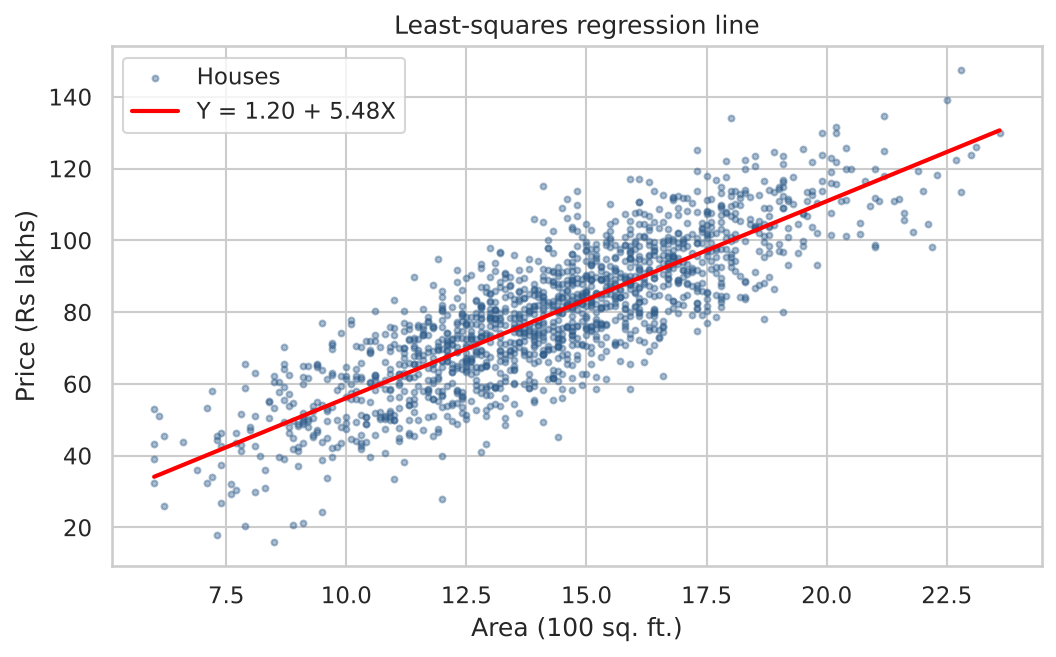

In [22]:
# Listing 5.3: Figure 5.1 - fitted regression line
xs = np.linspace(X.min(), X.max(), 100)
plt.figure(figsize=(8, 4.5))
plt.scatter(X, Y, s=8, alpha=.4, color='#2E5C8A', label='Houses')
plt.plot(xs, a + b*xs, color='red', lw=2, label=f'Y = {a:.2f} + {b:.2f}X')
plt.xlabel('Area (100 sq. ft.)'); plt.ylabel('Price (Rs lakhs)')
plt.title('Least-squares regression line'); plt.legend()
plt.savefig('fig/fig5_1_line.png'); plt.show()

In [23]:
# Listing 5.4: Multiple regression with statsmodels OLS
mlr = smf.ols('Price_Lakhs ~ Area_100SqFt + Bedrooms + Property_Age + Locality_Score',
              data=df).fit()
print(mlr.summary().tables[1])
print(f'R2 = {mlr.rsquared:.4f}, Adj R2 = {mlr.rsquared_adj:.4f}, '
      f'F = {mlr.fvalue:.1f}, AIC = {mlr.aic:.1f}')

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        -19.4719      1.403    -13.877      0.000     -22.224     -16.720
Area_100SqFt       3.9710      0.110     36.234      0.000       3.756       4.186
Bedrooms           5.0396      0.312     16.178      0.000       4.429       5.651
Property_Age      -0.6924      0.026    -26.486      0.000      -0.744      -0.641
Locality_Score    10.0139      0.297     33.756      0.000       9.432      10.596
R2 = 0.8744, Adj R2 = 0.8741, F = 2601.7, AIC = 10133.2


In [24]:
# Listing 5.5: Diagnostics - VIF, Breusch-Pagan, Jarque-Bera, Durbin-Watson
Xv = sm.add_constant(df[['Area_100SqFt', 'Bedrooms', 'Property_Age', 'Locality_Score']])
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=Xv.columns[1:])
print('VIF:'); print(vif.round(2))
bp = het_breuschpagan(mlr.resid, mlr.model.exog)
jb = stats.jarque_bera(mlr.resid)
print(f'Breusch-Pagan LM = {bp[0]:.2f}, p = {bp[1]:.3g}')
print(f'Jarque-Bera = {jb.statistic:.2f}, p = {jb.pvalue:.3g}')
print(f'Durbin-Watson = {sm.stats.durbin_watson(mlr.resid):.3f}')

VIF:
Area_100SqFt      3.31
Bedrooms          3.31
Property_Age      1.00
Locality_Score    1.00
dtype: float64
Breusch-Pagan LM = 5.94, p = 0.203
Jarque-Bera = 7.84, p = 0.0198
Durbin-Watson = 2.030


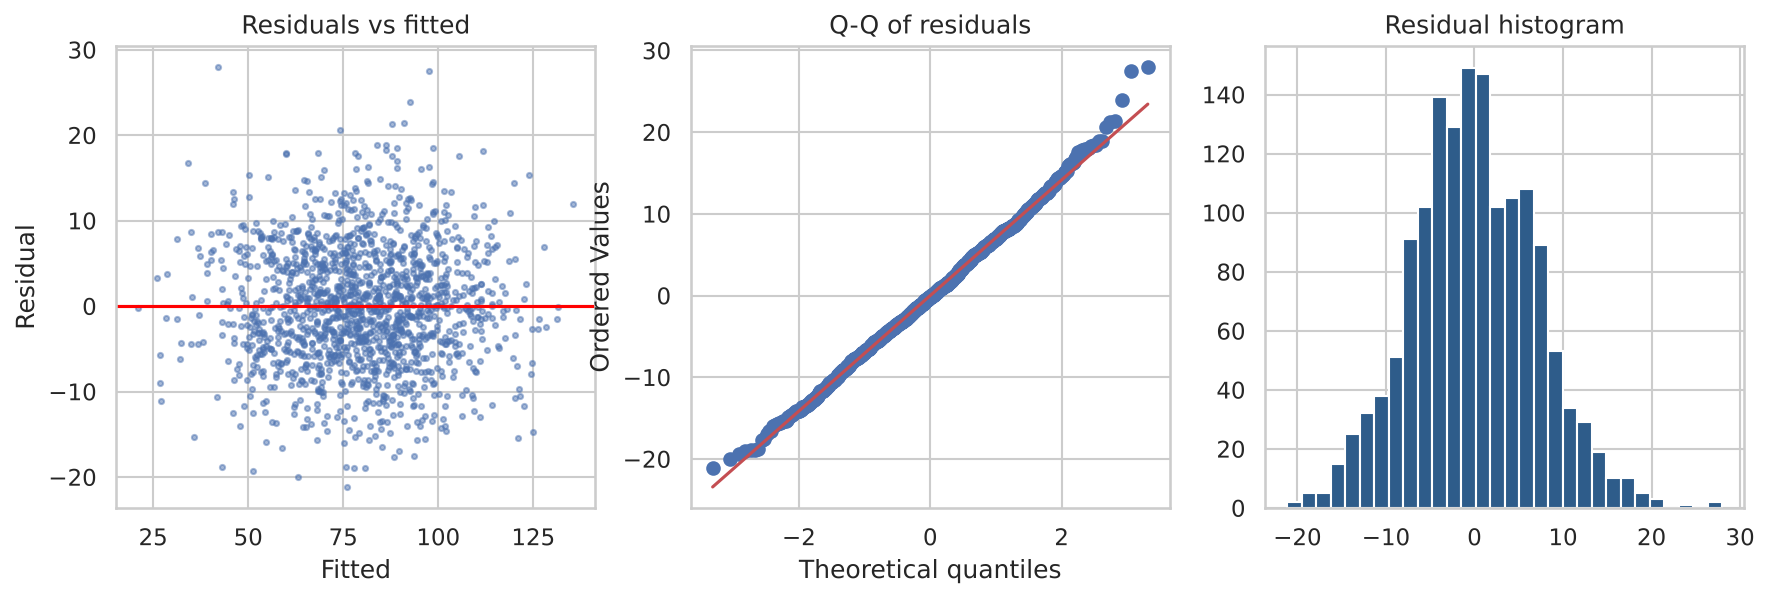

In [25]:
# Listing 5.6: Figure 5.2 - residual diagnostics
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].scatter(mlr.fittedvalues, mlr.resid, s=6, alpha=.5); ax[0].axhline(0, color='red')
ax[0].set_title('Residuals vs fitted'); ax[0].set_xlabel('Fitted'); ax[0].set_ylabel('Residual')
stats.probplot(mlr.resid, plot=ax[1]); ax[1].set_title('Q-Q of residuals')
ax[2].hist(mlr.resid, bins=30, color='#2E5C8A', edgecolor='white'); ax[2].set_title('Residual histogram')
plt.savefig('fig/fig5_2_resid.png'); plt.show()

In [26]:
# Listing 5.7: Train-test validation and 5-fold cross-validation
feats = ['Area_100SqFt', 'Bedrooms', 'Property_Age', 'Locality_Score']
Xtr, Xte, ytr, yte = train_test_split(df[feats], df['Price_Lakhs'], test_size=0.2, random_state=42)
rows = []
for name, cols in [('Baseline (mean)', None), ('Simple (area)', ['Area_100SqFt']), ('Multiple', feats)]:
    if cols is None:
        pred = np.full(len(yte), ytr.mean())
    else:
        pred = LinearRegression().fit(Xtr[cols], ytr).predict(Xte[cols])
    rows.append([name, r2_score(yte, pred), np.sqrt(mean_squared_error(yte, pred)),
                 mean_absolute_error(yte, pred), np.mean(np.abs((yte - pred) / yte)) * 100])
res = pd.DataFrame(rows, columns=['Model', 'Test R2', 'RMSE', 'MAE', 'MAPE_%'])
print(res.round(3).to_string(index=False))
cv = cross_val_score(LinearRegression(), df[feats], df['Price_Lakhs'], cv=5, scoring='r2')
print('5-fold CV R2:', cv.round(3), 'mean =', round(cv.mean(), 3))

          Model  Test R2   RMSE    MAE  MAPE_%
Baseline (mean)   -0.000 20.595 16.592  24.029
  Simple (area)    0.690 11.470  9.274  13.290
       Multiple    0.874  7.297  5.856   8.069
5-fold CV R2: [0.877 0.866 0.86  0.887 0.875] mean = 0.873


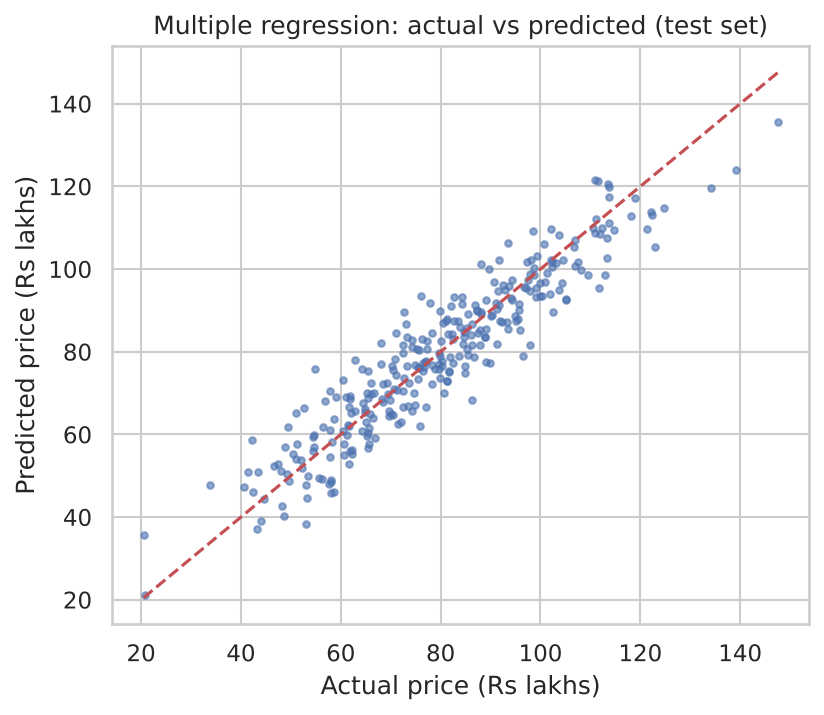

In [27]:
# Listing 5.8: Figure 5.3 - actual vs predicted on the test set
mfit = LinearRegression().fit(Xtr, ytr); pred = mfit.predict(Xte)
plt.figure(figsize=(6, 5))
plt.scatter(yte, pred, s=10, alpha=.6)
lim = [yte.min(), yte.max()]; plt.plot(lim, lim, 'r--')
plt.xlabel('Actual price (Rs lakhs)'); plt.ylabel('Predicted price (Rs lakhs)')
plt.title('Multiple regression: actual vs predicted (test set)')
plt.savefig('fig/fig5_3_pred.png'); plt.show()

## Chapter 6 · Prediction and Price Scenarios

Area-based scenarios from the simple model and buyer-profile predictions with 95% prediction intervals from the multiple model.

In [28]:
# Listing 6.1: Area-based price scenarios from the simple model
areas = [1000, 1250, 1500, 1750, 2000]
for ar in areas:
    print(f'{ar:5d} sq ft -> X = {ar/100:5.1f} -> Rs {a + b*ar/100:6.2f} lakhs')

 1000 sq ft -> X =  10.0 -> Rs  56.05 lakhs
 1250 sq ft -> X =  12.5 -> Rs  69.76 lakhs
 1500 sq ft -> X =  15.0 -> Rs  83.47 lakhs
 1750 sq ft -> X =  17.5 -> Rs  97.19 lakhs
 2000 sq ft -> X =  20.0 -> Rs 110.90 lakhs


In [29]:
# Listing 6.2: Prediction intervals for buyer profiles from the multiple model
profiles = pd.DataFrame({
    'Area_100SqFt':  [9.0, 12.0, 15.0, 15.0, 20.0],
    'Bedrooms':      [1, 2, 3, 3, 4],
    'Property_Age':  [15, 8, 5, 20, 2],
    'Locality_Score':[3.0, 3.5, 4.0, 3.0, 4.5]},
    index=['Starter 1 BHK', 'Family 2 BHK', 'New 3 BHK, good area',
           'Old 3 BHK, avg area', 'Premium 4 BHK'])
pr = mlr.get_prediction(profiles).summary_frame(alpha=0.05)
out = profiles.join(pr[['mean', 'obs_ci_lower', 'obs_ci_upper']].set_index(profiles.index))
print(out.round(2))

                      Area_100SqFt  Bedrooms  Property_Age  Locality_Score    mean  obs_ci_lower  obs_ci_upper
Starter 1 BHK                  9.0         1            15             3.0   40.96         27.05         54.87
Family 2 BHK                  12.0         2             8             3.5   67.77         53.87         81.66
New 3 BHK, good area          15.0         3             5             4.0   91.81         77.91        105.70
Old 3 BHK, avg area           15.0         3            20             3.0   71.41         57.50         85.31
Premium 4 BHK                 20.0         4             2             4.5  123.78        109.85        137.72


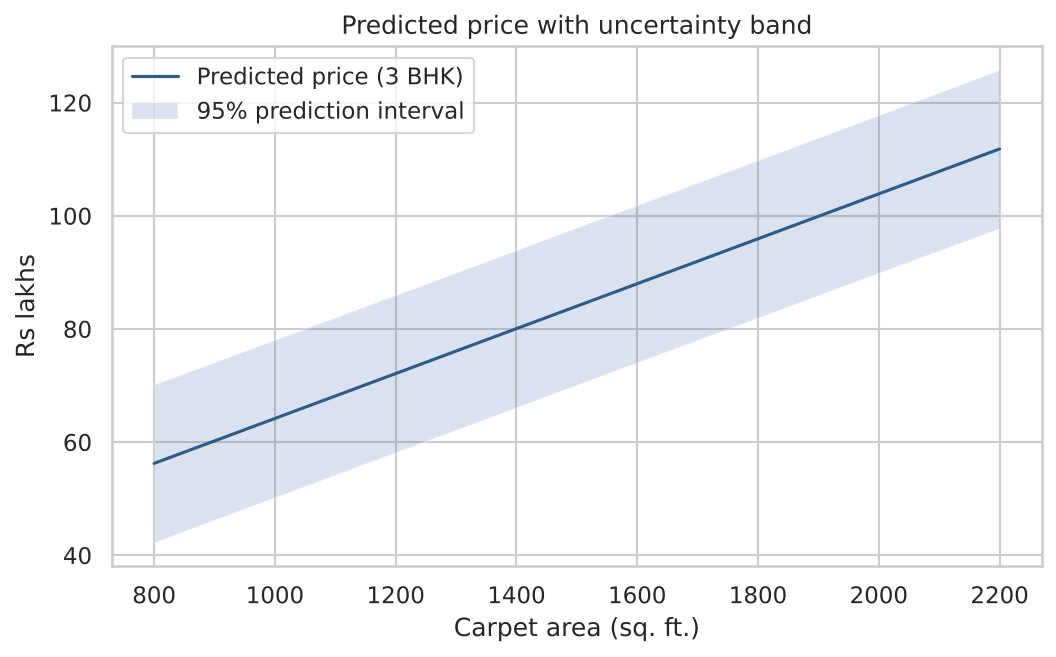

In [30]:
# Listing 6.3: Figure 6.1 - price-area curve with 95% prediction band
grid = pd.DataFrame({'Area_100SqFt': np.linspace(8, 22, 50), 'Bedrooms': 3,
                     'Property_Age': df['Property_Age'].median(),
                     'Locality_Score': df['Locality_Score'].median()})
gp = mlr.get_prediction(grid).summary_frame()
plt.figure(figsize=(8, 4.5))
plt.plot(grid['Area_100SqFt']*100, gp['mean'], color='#2E5C8A', label='Predicted price (3 BHK)')
plt.fill_between(grid['Area_100SqFt']*100, gp['obs_ci_lower'], gp['obs_ci_upper'],
                 alpha=.2, label='95% prediction interval')
plt.xlabel('Carpet area (sq. ft.)'); plt.ylabel('Rs lakhs'); plt.legend()
plt.title('Predicted price with uncertainty band')
plt.savefig('fig/fig6_1_band.png'); plt.show()

## Chapter 7 · Findings

One cell that regenerates every headline number of the report.

In [31]:
# Listing 7.1: Consolidated headline results
summary = {
    'N': len(df), 'Mean price': round(df['Price_Lakhs'].mean(), 2),
    'Median area': df['Area_SqFt'].median(), 'Mode BHK': int(df['Bedrooms'].mode().iloc[0]),
    'Spearman rho': round(rho, 3), 'Pearson r': round(r, 3),
    'Chi-square': round(chi2, 2), "Cramer's V": round(cramers_v, 3),
    'Simple eq': f'Y = {a:.2f} + {b:.2f}X', 'Simple R2': round(R2, 3),
    'Multiple R2': round(mlr.rsquared, 3), 'Test RMSE': round(res.iloc[2]['RMSE'], 2)}
for k_, v in summary.items():
    print(f'{k_:14s}: {v}')

N             : 1500
Mean price    : 79.49
Median area   : 1440.0
Mode BHK      : 3
Spearman rho  : 0.83
Pearson r     : 0.835
Chi-square    : 145.19
Cramer's V    : 0.22
Simple eq     : Y = 1.20 + 5.48X
Simple R2     : 0.697
Multiple R2   : 0.874
Test RMSE     : 7.3


## Key results
| Result | Value |
|---|---|
| Mean price / median price | ₹79.49 L / ₹79.70 L |
| Area vs price | Pearson r = 0.835, Spearman ρ = 0.830 |
| Zone type × price category | χ² = 145.19 (df = 4), Cramér's V = 0.22 |
| Urban vs suburban | Welch t = 9.70, Cohen's d = 0.55 |
| Simple model | Price = 1.20 + 5.48 × Area(100 sq ft), R² = 0.697 |
| Multiple model | R² = 0.874, test RMSE = ₹7.30 L, MAPE = 8.1% |

*Data are synthetic (seeded). Coefficients describe associations, not causal effects — re-run on recorded transaction data before real-world use.*